# Member 1 — Data audit, leakage audit & EDA
**Owner:** Member 1  
**Goal:** establish whether the data can be trusted before any model is trained.

Modules: `src/data_loader.py`, `src/leakage_audit.py`

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
from src import config as C
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
def show(name): display(Image(filename=str(C.FIG_DIR / f'{name}.png')))
def tbl(name): return pd.read_csv(C.TABLE_DIR / f'{name}.csv')

## 1. Load and profile

In [2]:
from src.data_loader import load_raw, load_clean, basic_profile, empty_or_constant_columns
raw = load_raw()
print('shape:', raw.shape, '| duplicates:', raw.duplicated().sum(), '| fraud rate:', round(raw.is_fraud.mean(), 4))
basic_profile(raw).head(65)

shape: (26393, 65) | duplicates: 0 | fraud rate: 0.1722


,column,dtype,missing_pct,n_unique,example
0,transaction_id,str,0.0,26393,7d4e9561-000c-44c8-84e4-54af2c4ac209
1,user_id,str,0.0,4818,michelle89
2,merchant_id,str,0.0,6544,8bdff36c-efba-4260-a801-8bd36f0f2eb0
3,amount,float64,0.0,26393,1960.754748
4,timestamp,str,0.0,18748,18:27.7
...,...,...,...,...,...
60,social_media_presence,str,0.0,1,none
61,handle_registration_pattern,str,0.0,2,none
62,handle_to_description_consistency,int64,0.0,2,0
63,handle_verification_status,str,0.0,2,verified


In [3]:
print('Empty (>=95% missing) or single-valued columns:')
empty_or_constant_columns(raw)

Empty (>=95% missing) or single-valued columns:


['url_referrer',
 'request_description',
 'relationship_to_requester',
 'upi_handle_age',
 'handle_contains_official_terms',
 'social_media_presence']

## 2. The timestamp problem
The `timestamp` column only holds `MM:SS.f` — the date and hour were lost (likely a spreadsheet export). A true chronological split is therefore impossible; we use a **user-grouped split** instead and build an *intra-day pseudo-order* (hour + mm:ss) for sequences.

In [4]:
print(raw.timestamp.sample(8, random_state=0).tolist())
df = load_clean()
df[['user_id','transaction_time_of_day','timestamp','mmss_seconds','order_key']].head(8)

['38:13.7', '18:24.8', '39:49.2', '19:02.9', '09:50.3', '21:26.5', '51:10.3', '45:38.4']


,user_id,transaction_time_of_day,timestamp,mmss_seconds,order_key
0,Apr-74,1,13:17.3,797.3,4397.3
1,Apr-74,6,08:47.7,527.7,22127.7
2,Apr-74,18,39:32.8,2372.8,67172.8
3,Apr-74,18,51:02.9,3062.9,67862.9
4,Apr-94,21,22:10.4,1330.4,76930.4
5,Apr-94,22,24:47.7,1487.7,80687.7
6,Apr-94,23,03:17.0,197.0,82997.0
7,Mar-13,2,09:00.8,540.8,7740.8


## 3. Leakage audit
### 3a. Single-feature AUC — can one column predict the label on its own?

In [5]:
from src.leakage_audit import single_feature_auc, legit_constant_columns, pure_levels, out_of_range
sfa = single_feature_auc(df); sfa.head(15)

,feature,auc,flag
0,handle_verification_status,1.0000,LABEL PROXY
1,receiver_account_age,0.9931,LABEL PROXY
2,receiver_transaction_history,0.9472,SUSPICIOUS
3,merchant_category_code,0.8812,
4,unusual_transaction_amount_flag,0.8366,
5,time_pressure_indicators,0.7547,
6,amount,0.7430,
7,keyboard_input_speed,0.7271,
8,input_timing_consistency,0.7185,
9,transaction_amount_vs_sender_history,0.6999,


In [6]:
pd.crosstab(df.handle_verification_status, df.is_fraud)   # a perfect label proxy

is_fraud,0,1
handle_verification_status,,
unverified,0,4545
verified,21848,0


### 3b. Scenario signatures — columns that are constant for every legitimate row

In [7]:
lc = legit_constant_columns(df)
print(len(lc), 'columns have one single value across all 21,848 legitimate rows')
lc.head(20)

39 columns have one single value across all 21,848 legitimate rows


,feature,legit_value,fraud_rows_with_other_value_pct
2,url_referrer,NaN,100.00
38,handle_verification_status,verified,100.00
21,request_description,NaN,100.00
14,unusual_transaction_amount_flag,0,67.33
26,time_pressure_indicators,0,50.94
11,authentication_attempt_count,1,37.25
36,handle_registration_pattern,none,35.89
16,otp_request_device_consistency,1,32.78
4,unusual_device_flag,0,32.78
5,unusual_ip_flag,0,31.88


### 3c. Interaction leakage — a pair of columns that is only *jointly* leaky

,feature_a,feature_b,equal_in_legit_pct,equal_in_fraud_pct,auc_of_abs_difference
0,geographic_disparity,geographic_location_vs_ip,100.0,35.89,0.8206


geographic_disparity single-feature AUC = 0.508
geographic_location_vs_ip single-feature AUC = 0.501


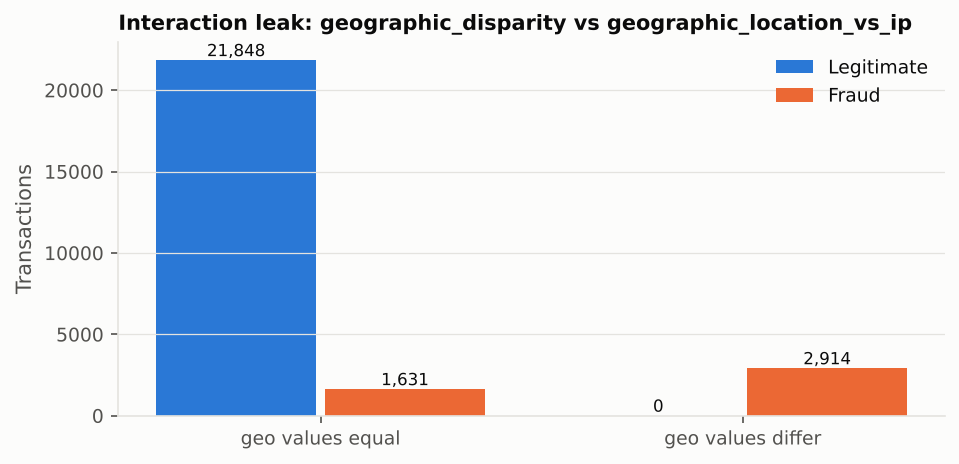

In [8]:
from src.leakage_audit import pairwise_equality
display(pairwise_equality(df))
for c in C.GEO_PAIR_COLS:
    from sklearn.metrics import roc_auc_score
    print(c, 'single-feature AUC =', round(roc_auc_score(df.is_fraud, df[c]), 3))
show('03b_geo_pair_interaction_leak')

Each geographic column alone is useless (AUC ≈ 0.50), yet the two are **identical in every legitimate row**. This leak was first spotted when the MLP's Integrated-Gradients ranking put these columns at the top (Member 5); it is excluded from the strict Tier 2.

### 3d. Behavioural features — fraud outside the legitimate range

In [9]:
out_of_range(df)

,feature,legit_min,legit_max,fraud_outside_pct
11,request_amount_roundness,0.997966,1.002551,63.94
4,input_timing_consistency,0.800014,0.999998,39.93
6,keyboard_input_speed,0.500052,1.499990,39.38
7,input_pause_patterns,0.000002,0.199999,31.88
9,background_data_usage,0.000003,0.499995,31.88
10,pin_entry_speed,0.500063,1.999998,31.35
0,amount,139.267664,10523.910200,27.68
1,session_duration,30.000000,300.000000,26.20
5,app_switching_frequency,0.000000,2.000000,19.45
8,screen_active_time,120.000000,600.000000,16.26


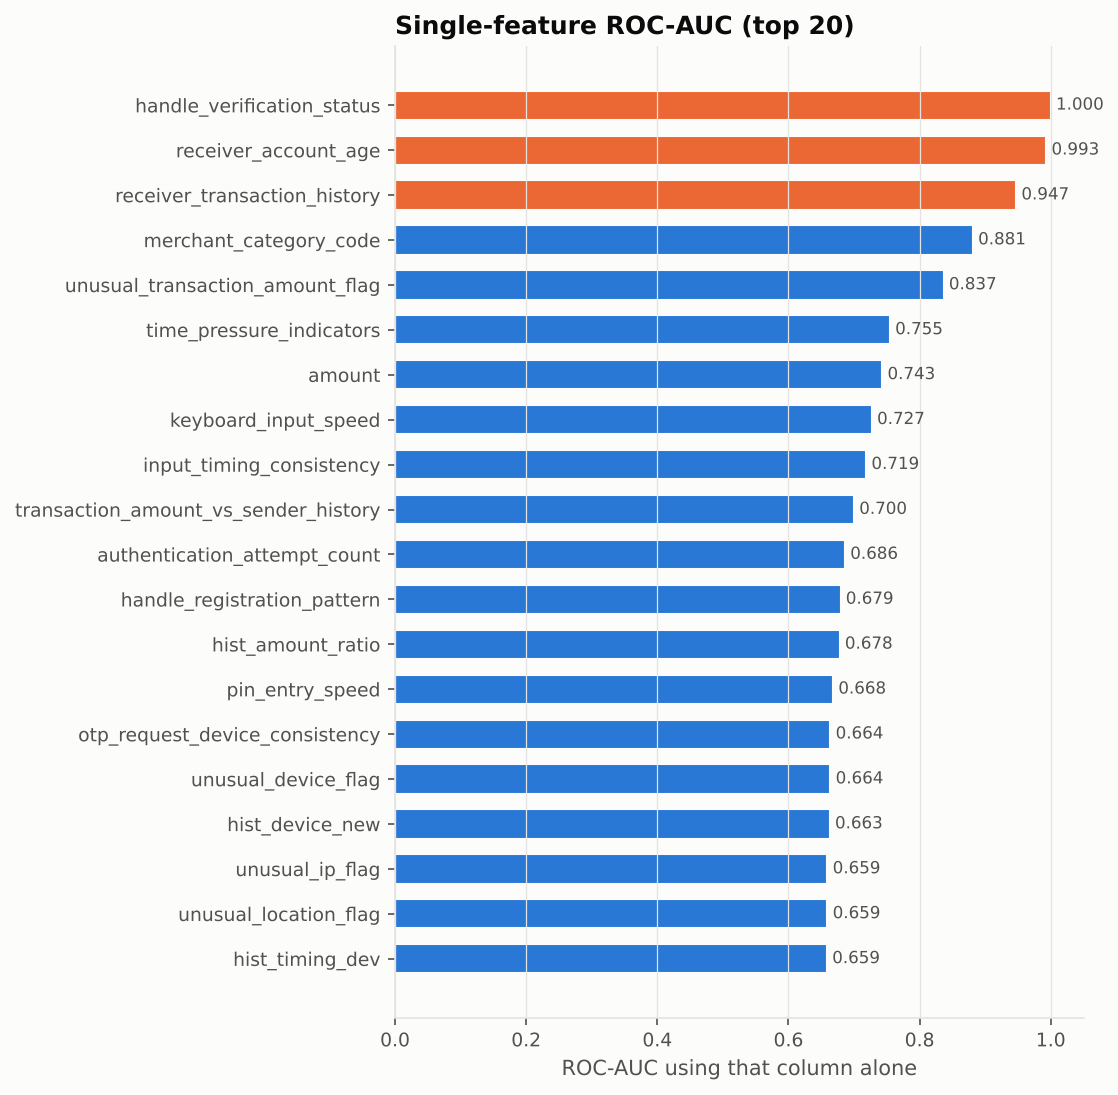

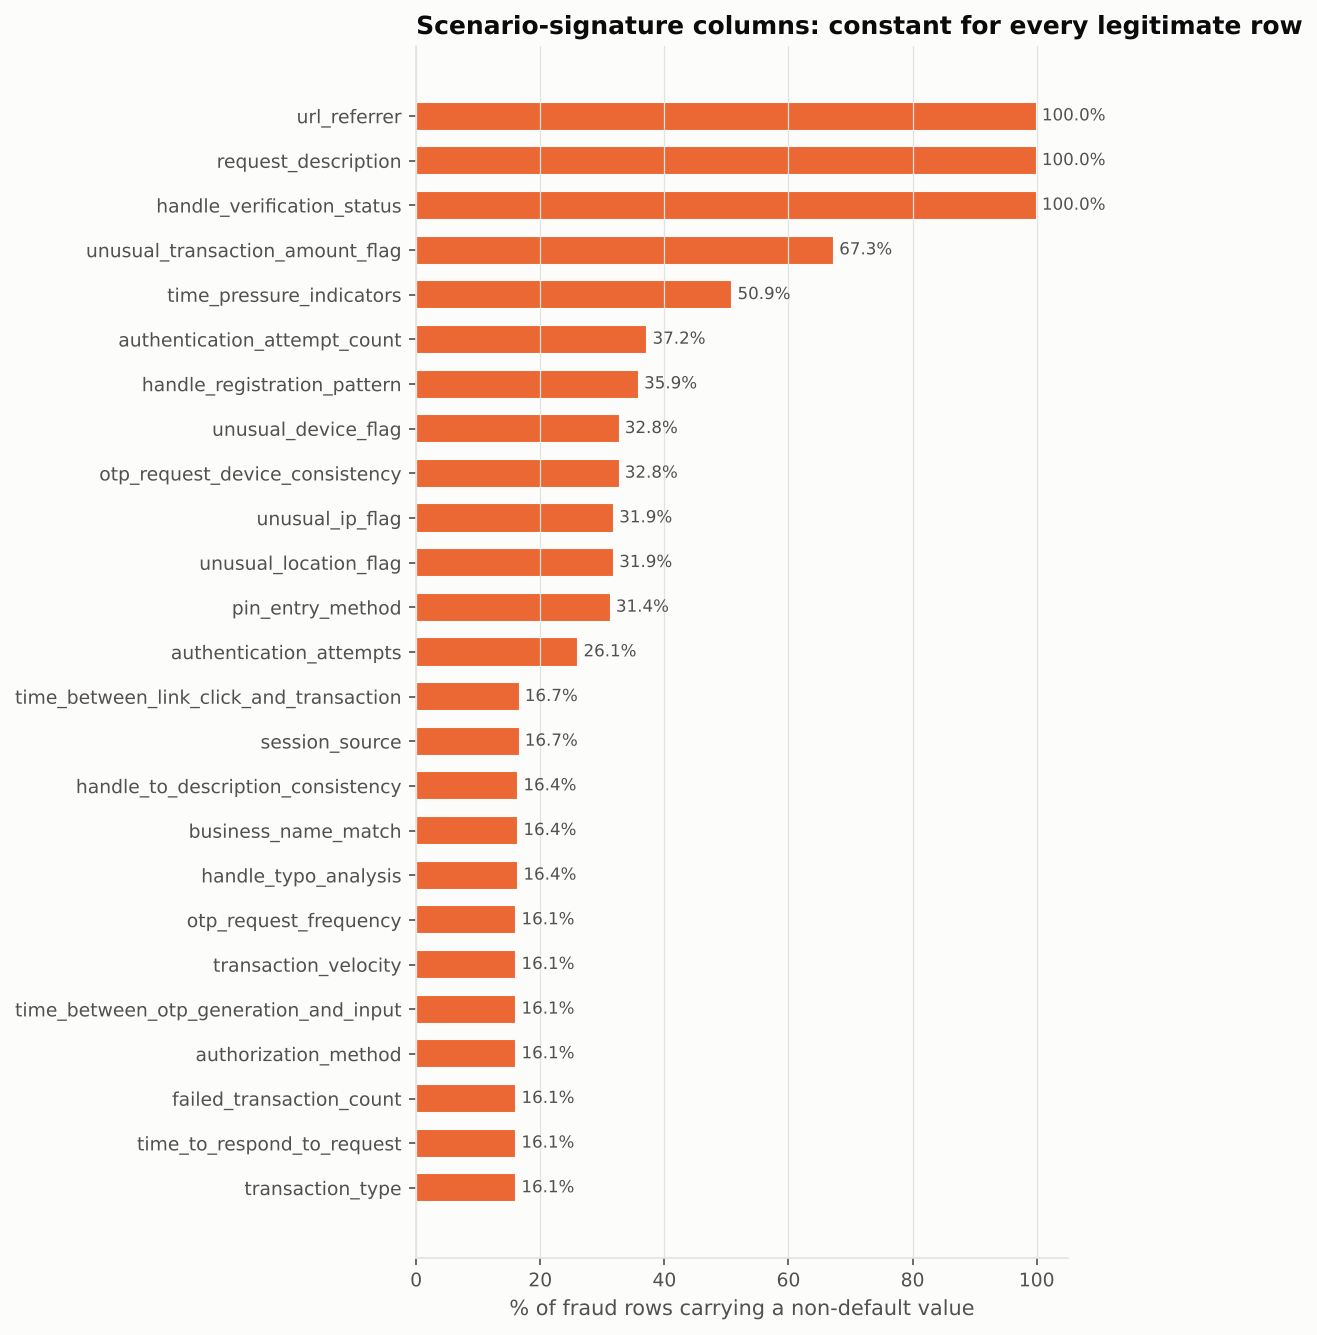

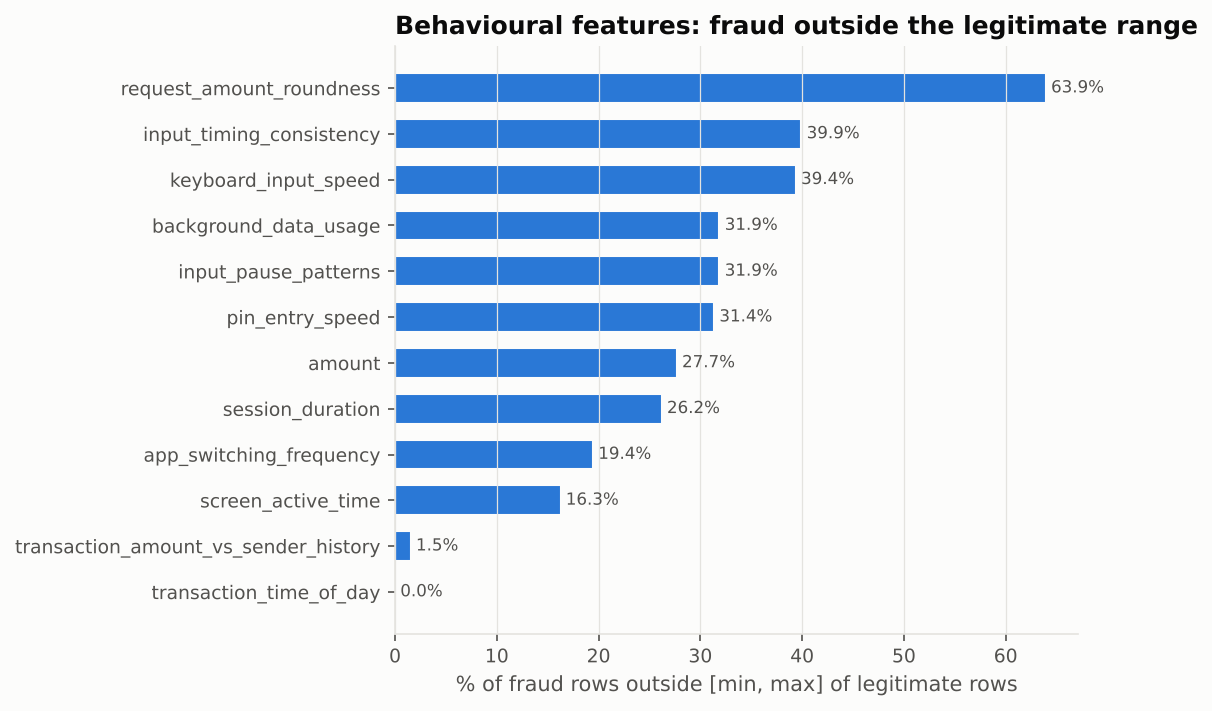

In [10]:
show('01_single_feature_auc'); show('02_legit_constant_columns'); show('03_out_of_range')

**Audit conclusion.** Three columns are label proxies (Tier 0 → Tier 1). A further 39 columns are scenario-injection artefacts, and one column pair leaks through its interaction. 12 behavioural / contextual columns remain; these form the strict Tier 2 used for the main comparison. Even these have hard range boundaries in the synthetic generator, which we quantify with a rule baseline and a *hard subset* evaluation.

## 4. Exploratory data analysis

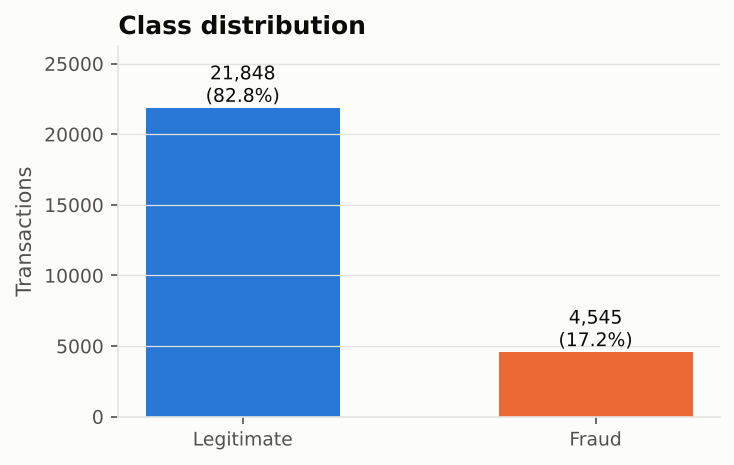

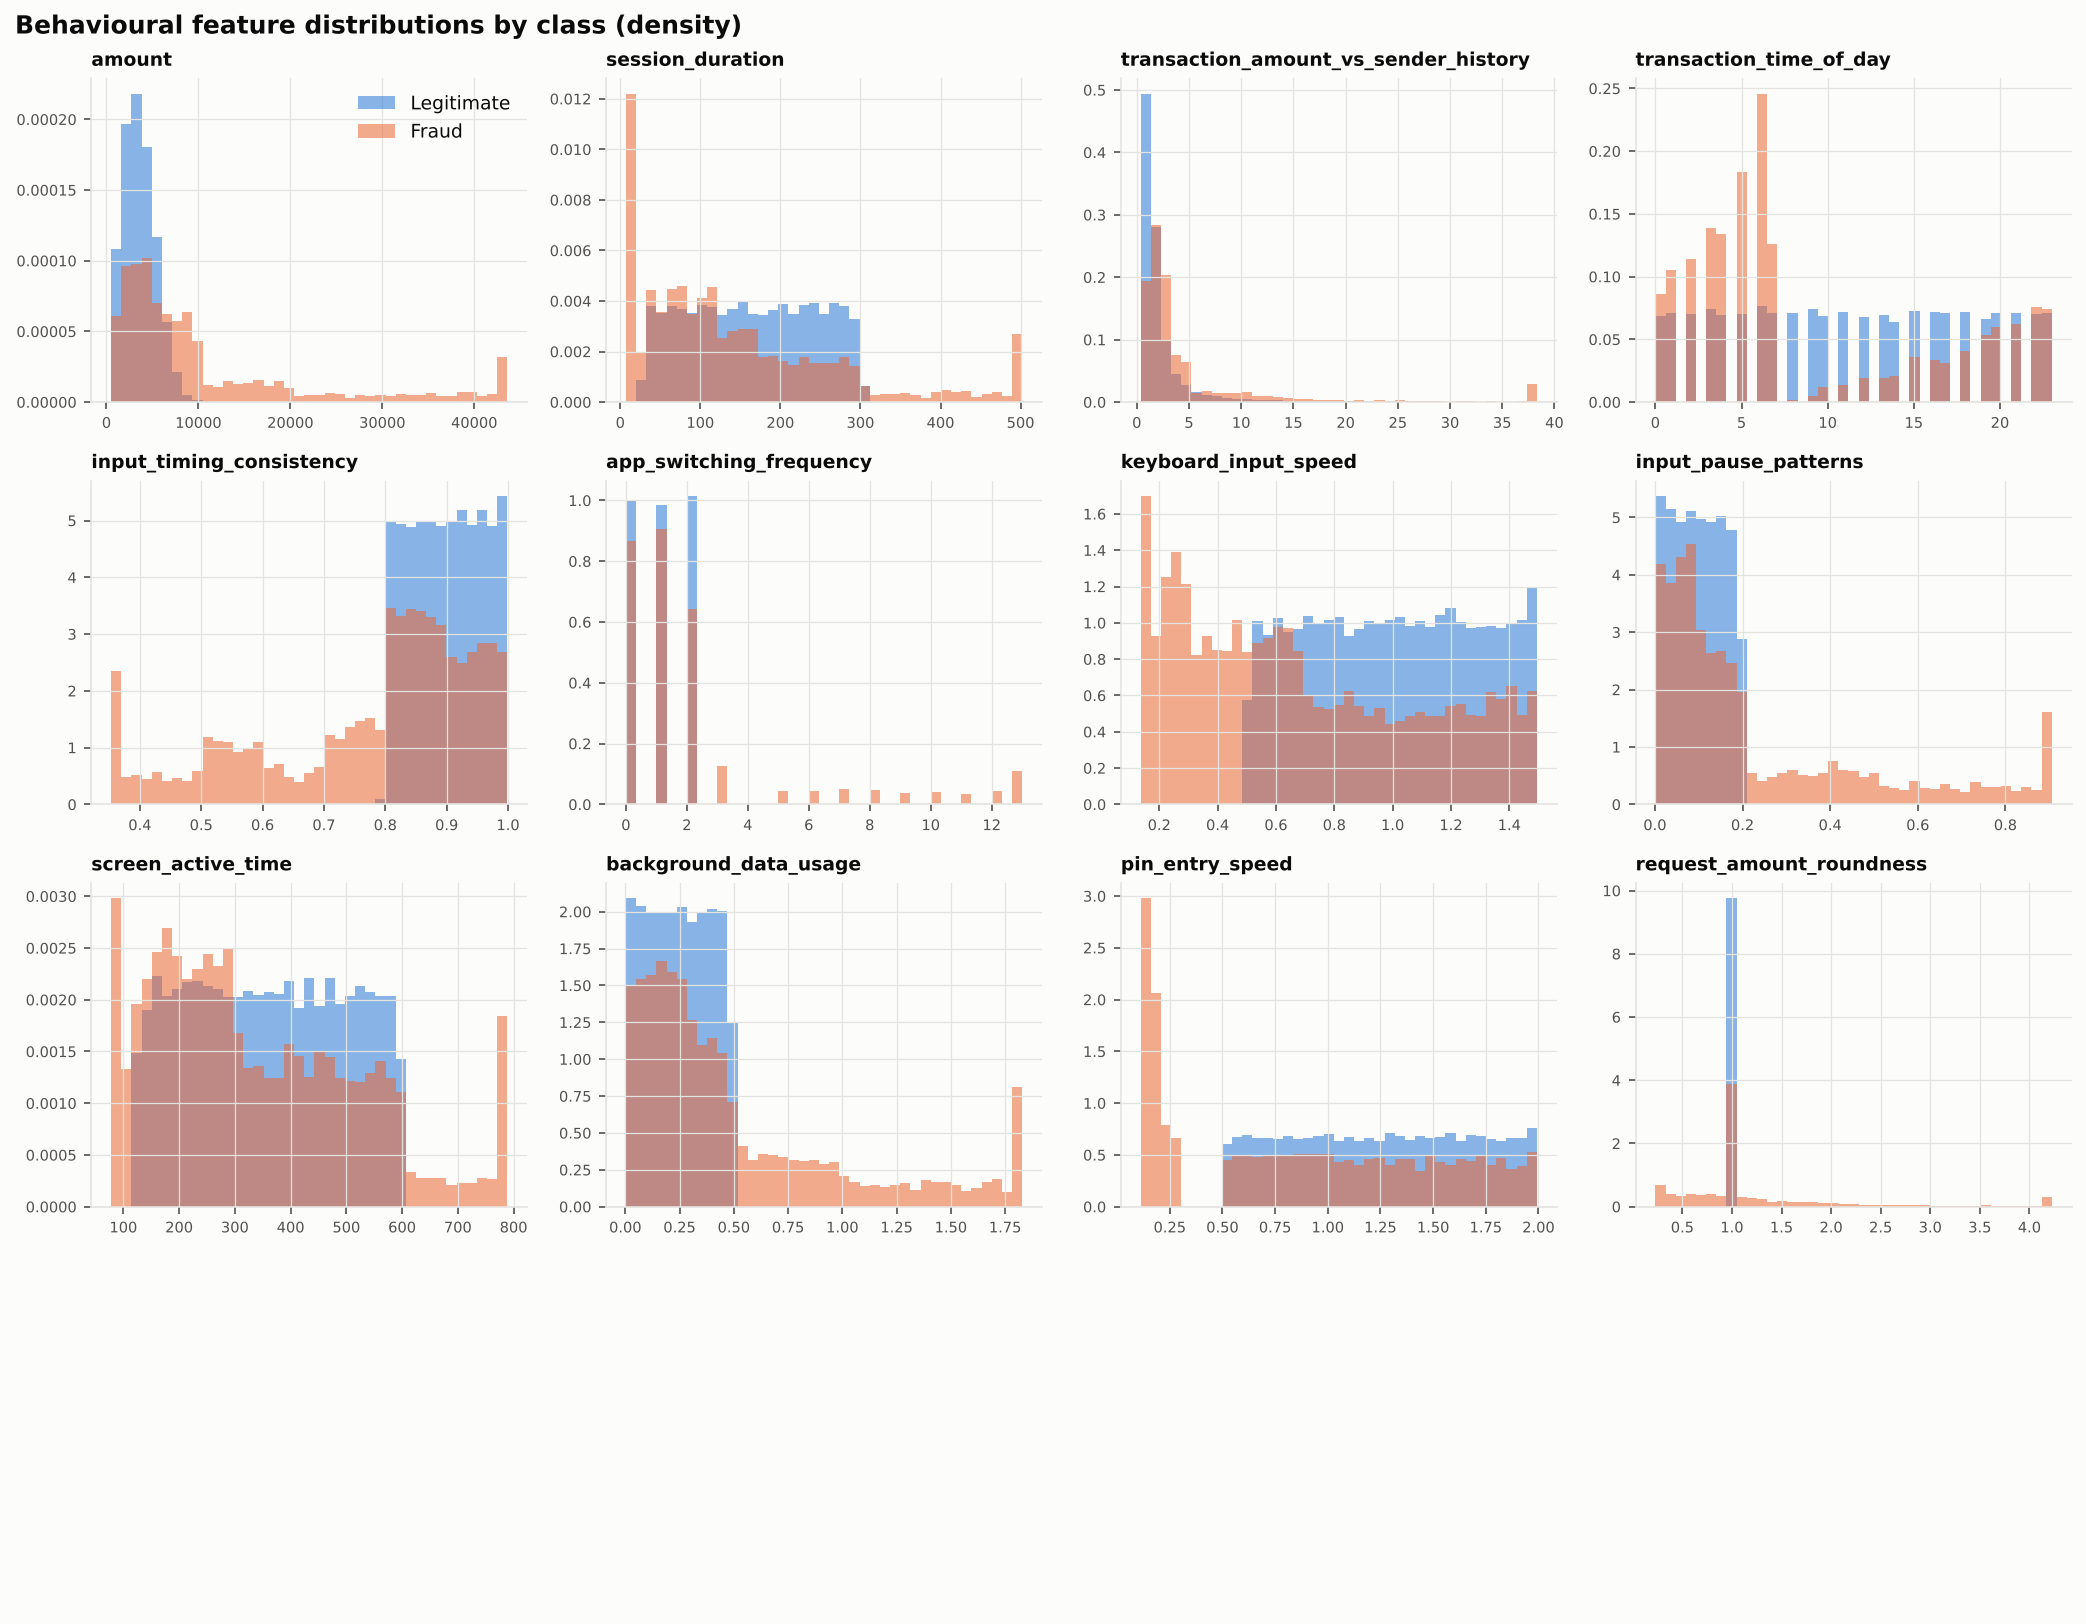

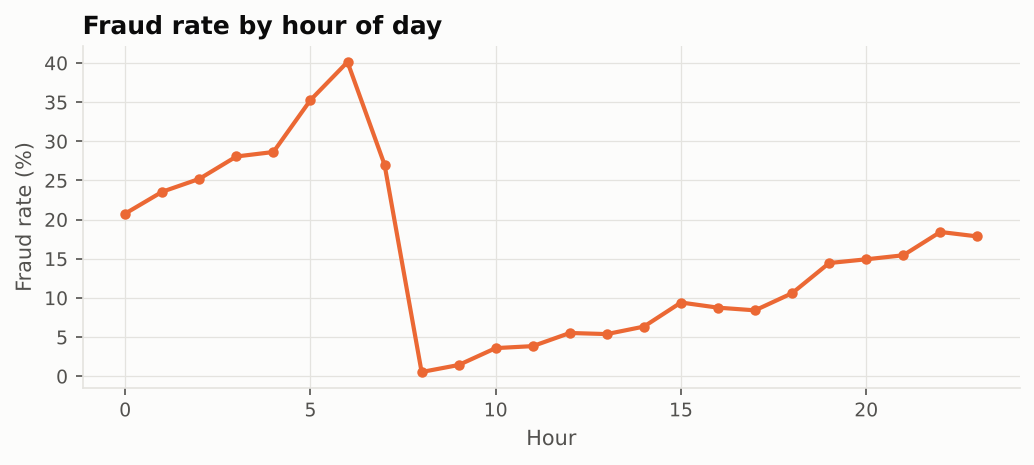

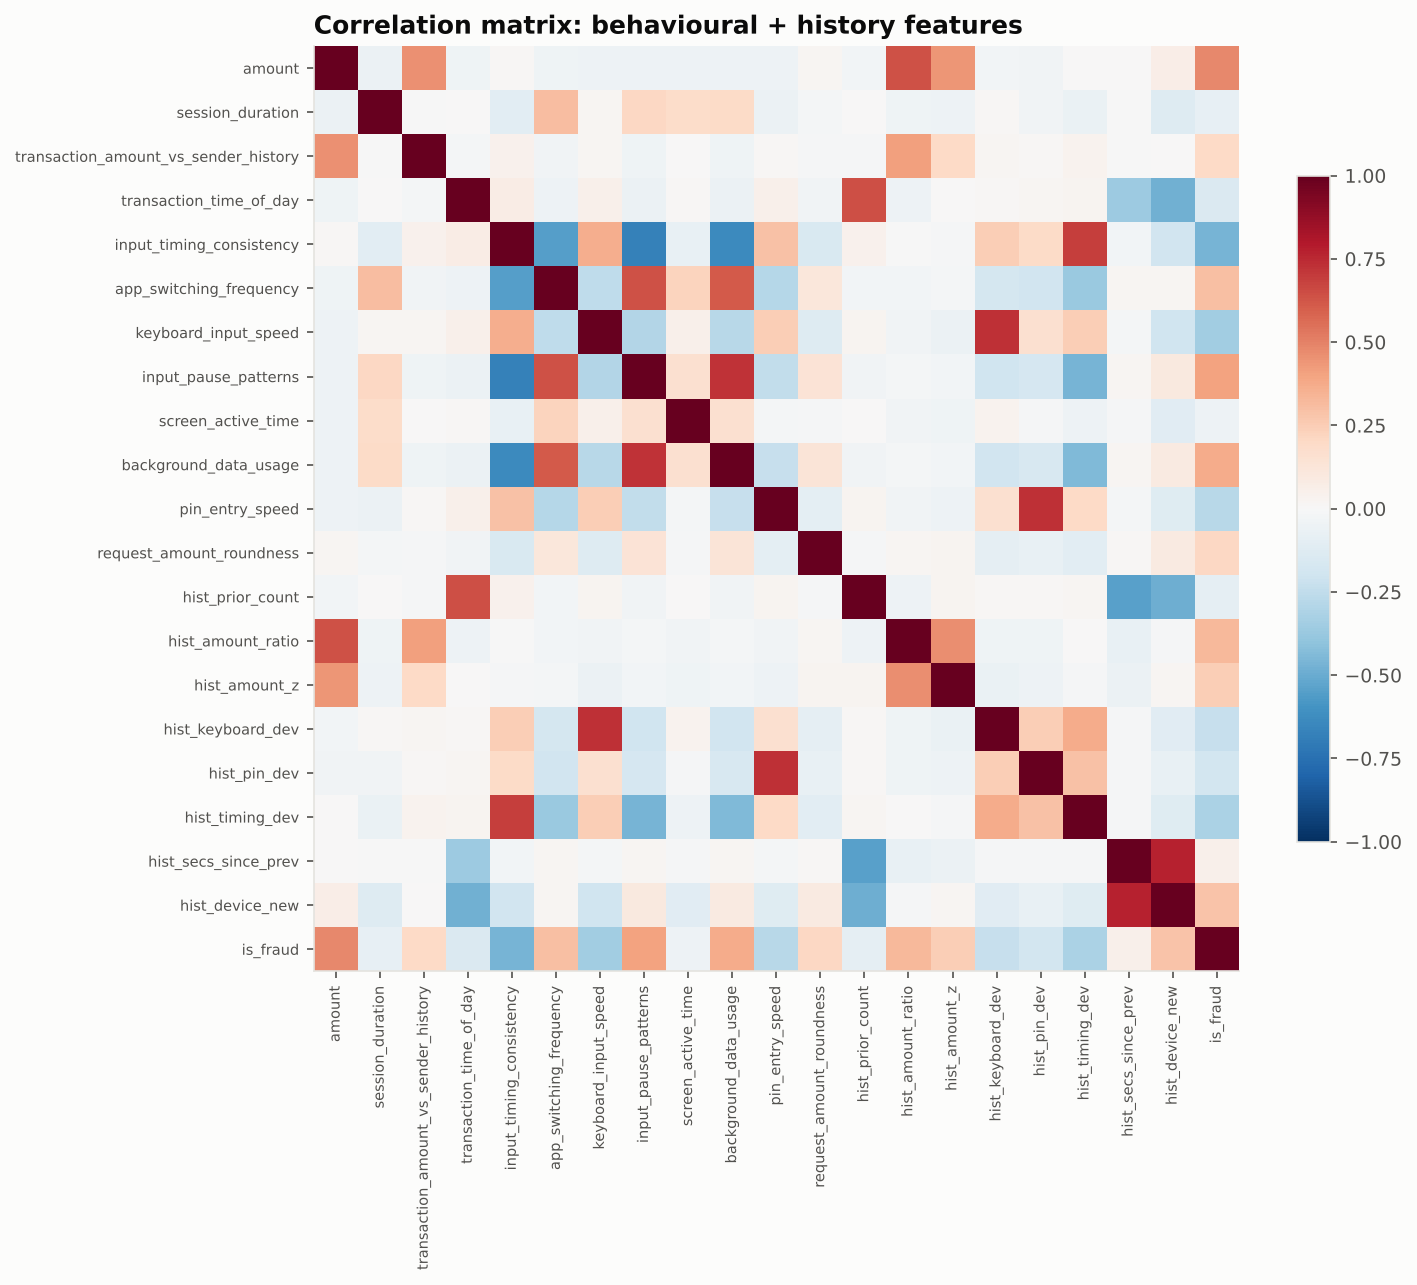

In [11]:
show('04_class_balance'); show('05_behavioural_distributions'); show('06_fraud_rate_by_hour'); show('07_correlation_matrix')

In [12]:
tbl('eda_medians_by_class')

,feature,median_legit,median_fraud
0,amount,3460.913626,6482.957050
1,session_duration,165.000000,110.000000
2,transaction_amount_vs_sender_history,1.380621,2.457720
3,transaction_time_of_day,11.000000,6.000000
4,input_timing_consistency,0.901062,0.829810
5,app_switching_frequency,1.000000,1.000000
6,keyboard_input_speed,1.002358,0.616231
7,input_pause_patterns,0.098433,0.131300
8,screen_active_time,359.000000,294.000000
9,background_data_usage,0.249253,0.330313


## 5. Experiment 1 result — how much does leakage inflate performance?

,model,setting,n_features,pr_auc,roc_auc,precision,recall,f1
0,Logistic Regression,T0_all_features,49,1.0000,1.0000,1.0000,1.0000,1.0000
1,XGBoost,T0_all_features,49,1.0000,1.0000,1.0000,1.0000,1.0000
2,MLP,T0_all_features,49,1.0000,1.0000,1.0000,1.0000,1.0000
3,Logistic Regression,T1_proxies_removed,46,1.0000,1.0000,1.0000,1.0000,1.0000
4,XGBoost,T1_proxies_removed,46,1.0000,1.0000,1.0000,1.0000,1.0000
5,MLP,T1_proxies_removed,46,1.0000,1.0000,1.0000,0.9990,0.9995
6,Logistic Regression,T2a_behavioural_with_geo_pair,14,0.8681,0.9182,0.8945,0.7518,0.8170
7,XGBoost,T2a_behavioural_with_geo_pair,14,0.9489,0.9673,0.9847,0.8728,0.9254
8,MLP,T2a_behavioural_with_geo_pair,14,0.9408,0.9629,0.9892,0.8571,0.9184
9,Logistic Regression,T2_behavioural,12,0.8678,0.9182,0.8947,0.7529,0.8177


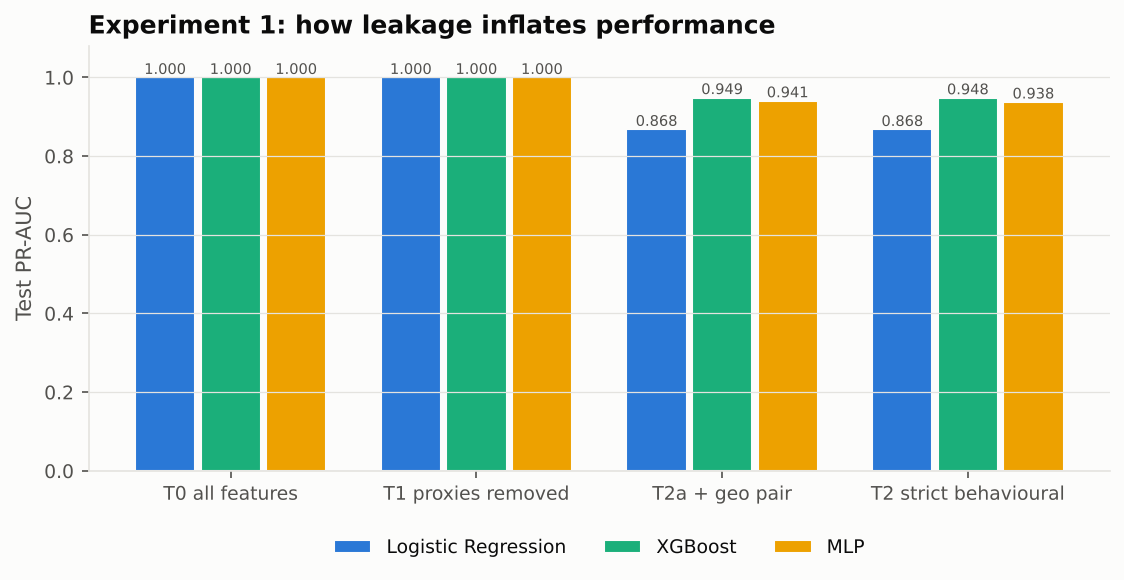

In [13]:
display(tbl('exp1_leakage_tiers')[['model','setting','n_features','pr_auc','roc_auc','precision','recall','f1']]); show('10_exp1_leakage')